Ширтанов Роман, группа 306

Импорт библиотек

In [1]:
import os
import copy
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


Импорт датасета

In [10]:
data = '/Users/romanshirtanov/Downloads/Mushrooms'

image_size = 224
batch_size = 32
epochs = 20
learning_rate = 0.0001
num_workers = 0

Обработка изображений

In [3]:
weights = models.ResNet18_Weights.DEFAULT

mean = weights.transforms().mean
std = weights.transforms().std

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

test_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

Загрузка датасета и разделение на train, test и validation

In [4]:
dataset = datasets.ImageFolder(data)

class_names = dataset.classes
num_classes = len(class_names)

indices = np.arange(len(dataset))
targets = np.array(dataset.targets)

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=SEED,
    stratify=targets
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.15,
    random_state=SEED,
    stratify=targets[train_val_idx]
)

train_data = datasets.ImageFolder(
    data,
    transform=train_transform
)

test_data = datasets.ImageFolder(
    data,
    transform=test_transform
)

train_data = datasets.ImageFolder(
    data,
    transform=train_transform
)

test_data = datasets.ImageFolder(
    data,
    transform=test_transform
)

train_dataset = Subset(train_data, train_idx)
val_dataset = Subset(test_data, val_idx)
test_dataset = Subset(test_data, test_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 4850
Validation: 856
Test: 1008


Создание модели

In [5]:
model = models.resnet18(weights=weights)

for param in model.parameters():
    param.requires_grad = False

in_features = model.fc.in_features

model.fc = nn.Linear(
    in_features,
    num_classes
)

model = model.to(device)

Функция потерь + функция обучения

In [6]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=learning_rate
)

def train_one_epoch(model, loader):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()

        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc


Функция проверки модели

In [8]:
def evaluate(model, loader):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

Обучение модели

In [11]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_loss = float("inf")

best_weights = copy.deepcopy(model.state_dict())

for epoch in range(epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_weights = copy.deepcopy(
            model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

model.load_state_dict(best_weights)

Epoch [1/20] Train Loss: 1.2099 Train Acc: 0.6074 Val Loss: 1.2226 Val Acc: 0.6051
Epoch [2/20] Train Loss: 1.1920 Train Acc: 0.6155 Val Loss: 1.1987 Val Acc: 0.6028
Epoch [3/20] Train Loss: 1.1609 Train Acc: 0.6229 Val Loss: 1.1823 Val Acc: 0.6157
Epoch [4/20] Train Loss: 1.1464 Train Acc: 0.6247 Val Loss: 1.1643 Val Acc: 0.6145
Epoch [5/20] Train Loss: 1.1251 Train Acc: 0.6320 Val Loss: 1.1500 Val Acc: 0.6168
Epoch [6/20] Train Loss: 1.1095 Train Acc: 0.6338 Val Loss: 1.1329 Val Acc: 0.6308
Epoch [7/20] Train Loss: 1.0959 Train Acc: 0.6445 Val Loss: 1.1111 Val Acc: 0.6332
Epoch [8/20] Train Loss: 1.0717 Train Acc: 0.6460 Val Loss: 1.1056 Val Acc: 0.6273
Epoch [9/20] Train Loss: 1.0623 Train Acc: 0.6536 Val Loss: 1.0886 Val Acc: 0.6437
Epoch [10/20] Train Loss: 1.0571 Train Acc: 0.6520 Val Loss: 1.0741 Val Acc: 0.6495
Epoch [11/20] Train Loss: 1.0519 Train Acc: 0.6489 Val Loss: 1.0737 Val Acc: 0.6437
Epoch [12/20] Train Loss: 1.0261 Train Acc: 0.6656 Val Loss: 1.0674 Val Acc: 0.6565
E

<All keys matched successfully>

Loss-кривая

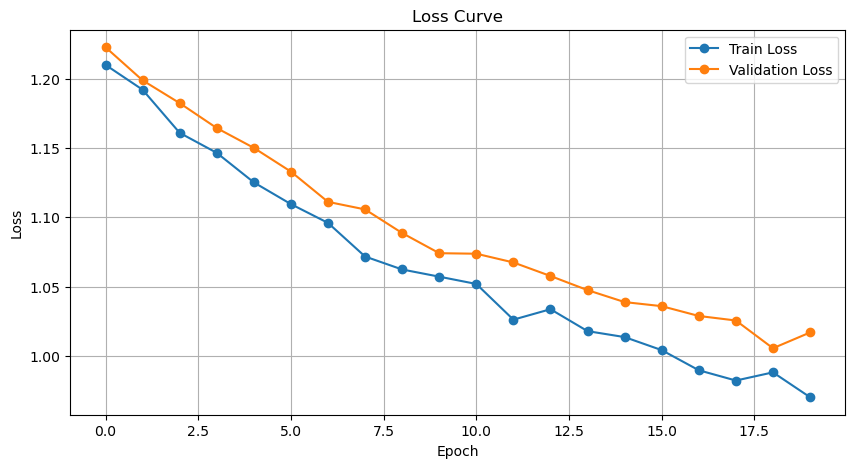

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Train Loss",
    marker="o"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

Accuracy-кривая

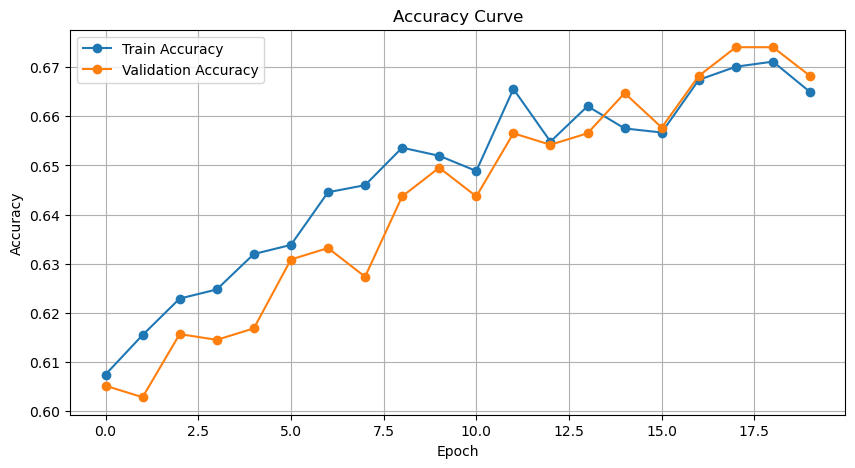

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_acc"],
    label="Train Accuracy",
    marker="o"
)

plt.plot(
    history["val_acc"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

Финальная Accuracy на тестовой выборке

In [15]:
model.eval()

test_predictions = []
test_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_labels.extend(
            labels.numpy()
        )

final_accuracy = accuracy_score(
    test_labels,
    test_predictions
)

print("FINAL TEST ACCURACY:")
print(f"{final_accuracy * 100:.2f}%")

FINAL TEST ACCURACY:
67.86%


Проверка на Train выборке

In [17]:
train_eval_dataset = Subset(
    test_data,
    train_idx
)

train_eval_loader = DataLoader(
    train_eval_dataset,
    batch_size=batch_size,
    shuffle=False
)

train_predictions = []
train_labels = []

model.eval()

with torch.no_grad():

    for images, labels in train_eval_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(
            predictions.cpu().numpy()
        )

        train_labels.extend(
            labels.numpy()
        )

train_accuracy = accuracy_score(
    train_labels,
    train_predictions
)

print("TRAIN ACCURACY:")
print(f"{train_accuracy * 100:.2f}%")

TRAIN ACCURACY:
69.01%


Сравнение Accuracy у Train и Test

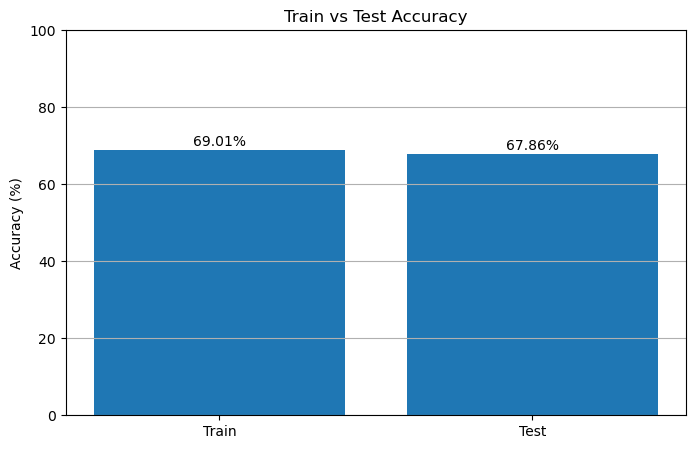

In [18]:
plt.figure(figsize=(8, 5))

names = ["Train", "Test"]

values = [
    train_accuracy * 100,
    final_accuracy * 100
]

bars = plt.bar(names, values)

plt.title("Train vs Test Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y")
plt.show()

Матрица ошибок

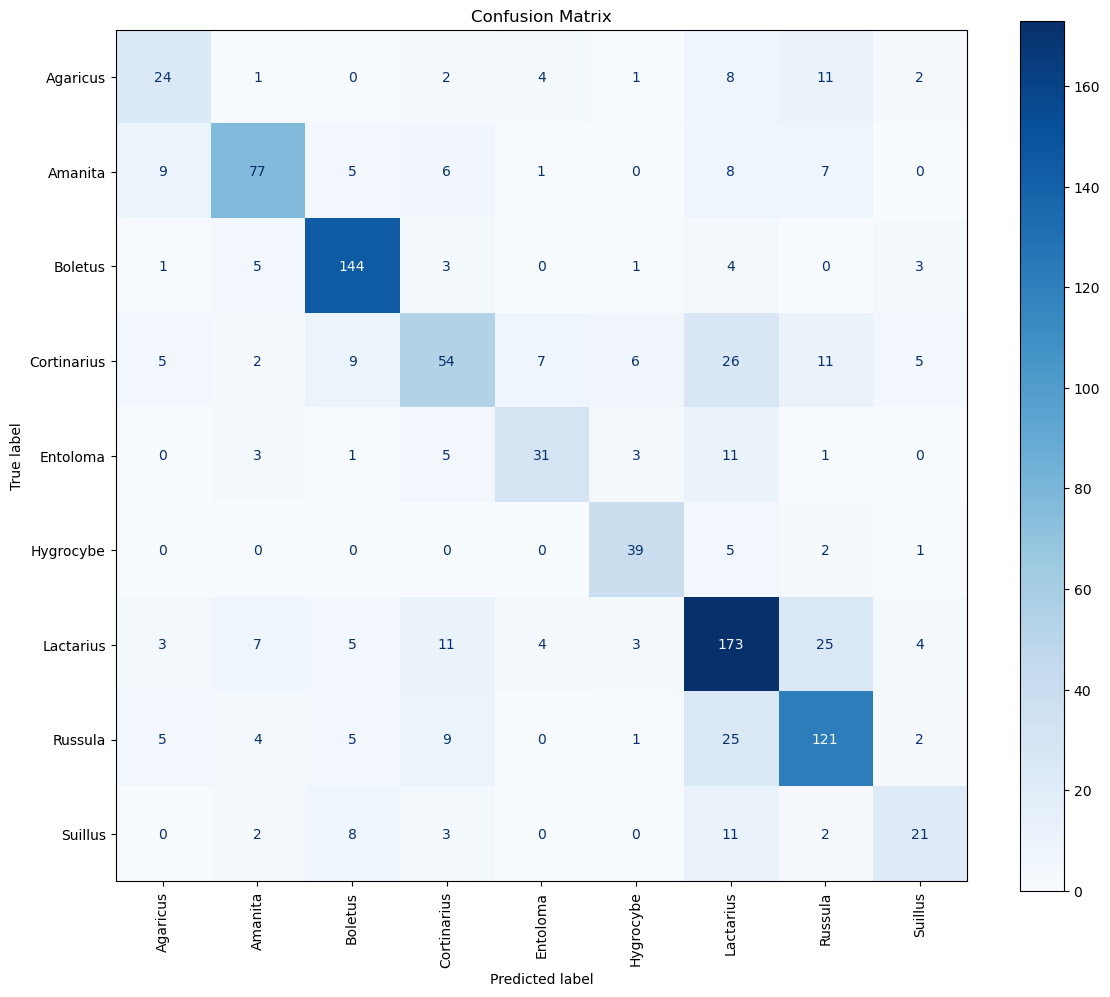

In [19]:
cm = confusion_matrix(
    test_labels,
    test_predictions
)

fig, ax = plt.subplots(
    figsize=(12, 10)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90
)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

Визуализация результатов

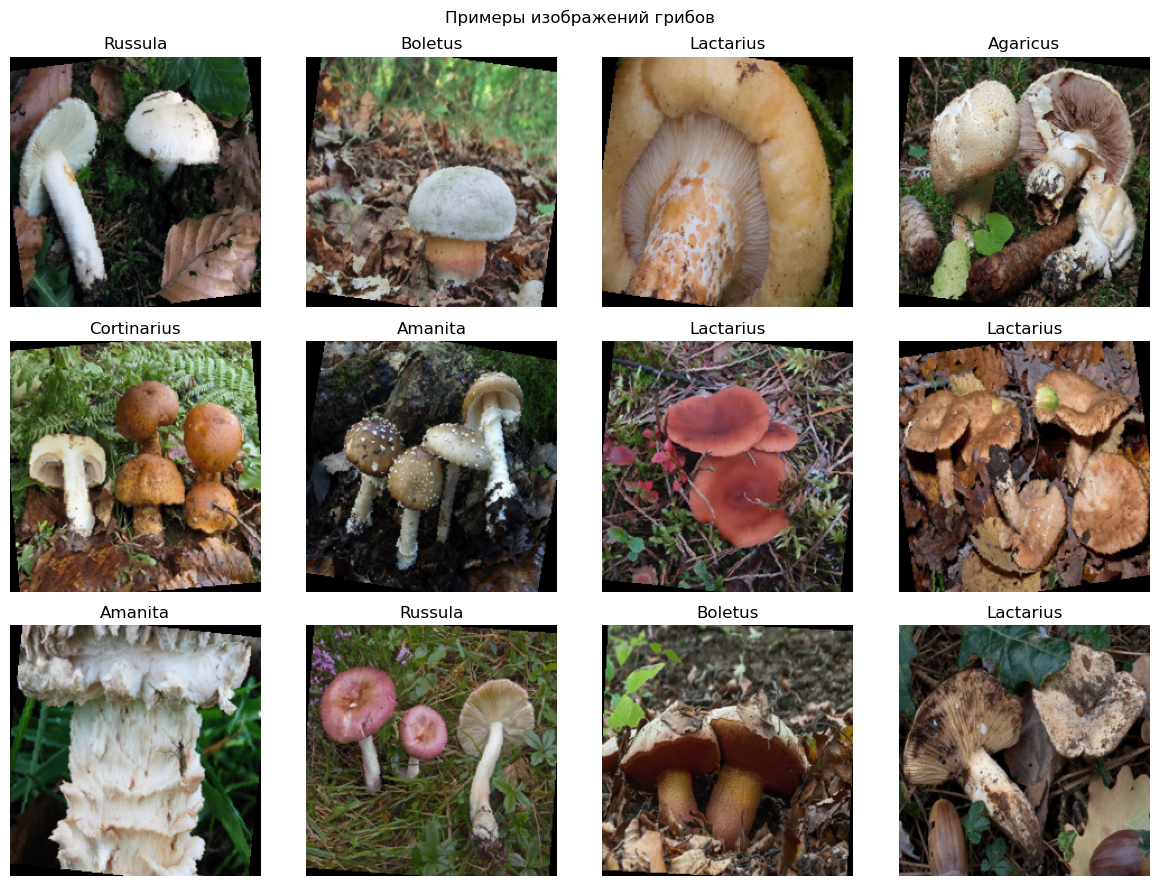

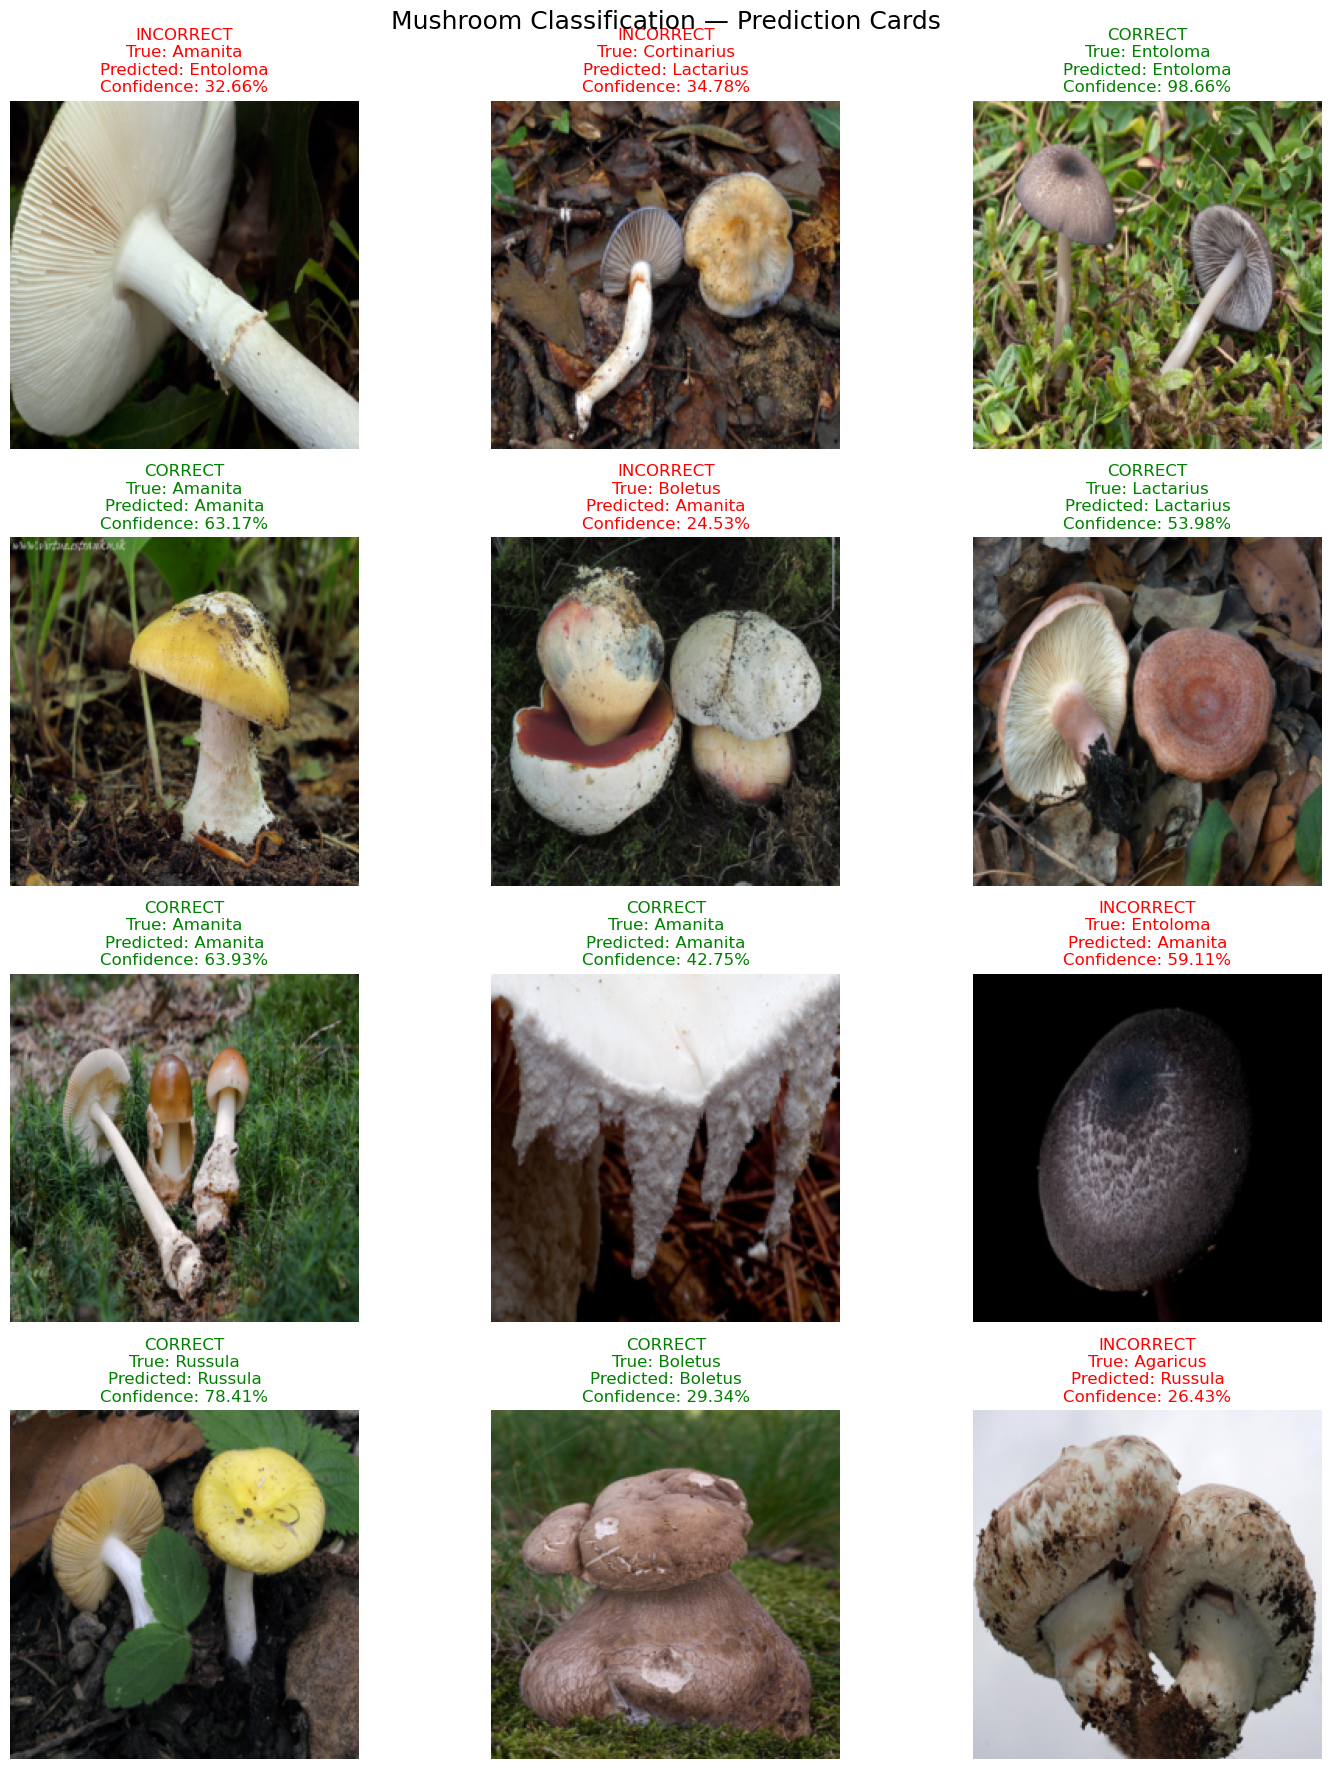

In [25]:
def denormalize(images):
    mean_tensor = torch.tensor(mean).view(1, 3, 1, 1)
    std_tensor = torch.tensor(std).view(1, 3, 1, 1)

    return (images.cpu() * std_tensor + mean_tensor).clamp(0, 1)


images, labels = next(iter(train_loader))

images = denormalize(images[:12])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, img, label in zip(
    axes.flat, images, labels[:12]
):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[label.item()])
    ax.axis("off")

plt.suptitle("Примеры изображений грибов")
plt.tight_layout()
plt.show()

model.eval()

cards = []

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images.to(device))

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        confidence, predictions = probabilities.max(dim=1)

        for image, label, pred, conf in zip(
            images,
            labels,
            predictions.cpu(),
            confidence.cpu()
        ):

            cards.append((
                image,
                label.item(),
                pred.item(),
                conf.item()
            ))

            if len(cards) >= 12:
                break

        if len(cards) >= 12:
            break


fig, axes = plt.subplots(
    4, 3,
    figsize=(15, 18)
)

for ax, (image, true_label, pred_label, confidence) in zip(
    axes.flat,
    cards
):

    image = denormalize(
        image.unsqueeze(0)
    )[0]

    image = image.permute(1, 2, 0)

    ax.imshow(image)

    correct = true_label == pred_label

    status = "CORRECT" if correct else "INCORRECT"

    color = "green" if correct else "red"

    ax.set_title(
        f"{status}\n"
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[pred_label]}\n"
        f"Confidence: {confidence:.2%}",
        color=color
    )

    ax.axis("off")

plt.suptitle(
    "Mushroom Classification — Prediction Cards",
    fontsize=18
)

plt.tight_layout()
plt.show()

Результаты

In [26]:
import pandas as pd

results = pd.DataFrame({
    "Metric": [
        "Train Accuracy",
        "Test Accuracy",
        "Best Validation Loss",
        "Number of Classes",
        "Train Images",
        "Validation Images",
        "Test Images"
    ],

    "Value": [
        f"{train_accuracy * 100:.2f}%",
        f"{final_accuracy * 100:.2f}%",
        f"{best_val_loss:.4f}",
        num_classes,
        len(train_dataset),
        len(val_dataset),
        len(test_dataset)
    ]
})

display(results)

,Metric,Value
0,Train Accuracy,69.01%
1,Test Accuracy,67.86%
2,Best Validation Loss,1.0055
3,Number of Classes,9
4,Train Images,4850
5,Validation Images,856
6,Test Images,1008
